# 01 - Framing and exploratory analysis

**Business question:** which customers are likely to churn, early enough for the business to act, and what should it do about it?

This dataset (IBM Telco Customer Churn, ~7,000 customers) is a stand-in for a pay-as-you-go style business: recurring payments, plan and contract choices, and a churn outcome. It is **not** PAYG LPG or solar data, and nothing here should be read as a claim about those businesses.

**Success is measured in commercial terms**: churners captured per customer contacted, and net value after contact costs, not AUC alone.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from telco_churn.data import load_clean

df = load_clean()
print(df.shape, "| overall churn rate:", round(df.Churn.mean(), 3))
print("Blank TotalCharges set to 0 (tenure-0 customers):", df.attrs["blank_total_charges"])
df.head()

(7043, 20) | overall churn rate: 0.265
Blank TotalCharges set to 0 (tenure-0 customers): 11


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## Where does churn concentrate?

In [2]:
for col in ["Contract", "PaymentMethod", "InternetService"]:
    t = df.groupby(col).Churn.agg(customers="size", churn_rate="mean").round(3)
    print(t, "\n")

                customers  churn_rate
Contract                             
Month-to-month       3875       0.427
One year             1473       0.113
Two year             1695       0.028 

                           customers  churn_rate
PaymentMethod                                   
Bank transfer (automatic)       1544       0.167
Credit card (automatic)         1522       0.152
Electronic check                2365       0.453
Mailed check                    1612       0.191 

                 customers  churn_rate
InternetService                       
DSL                   2421       0.190
Fiber optic           3096       0.419
No                    1526       0.074 



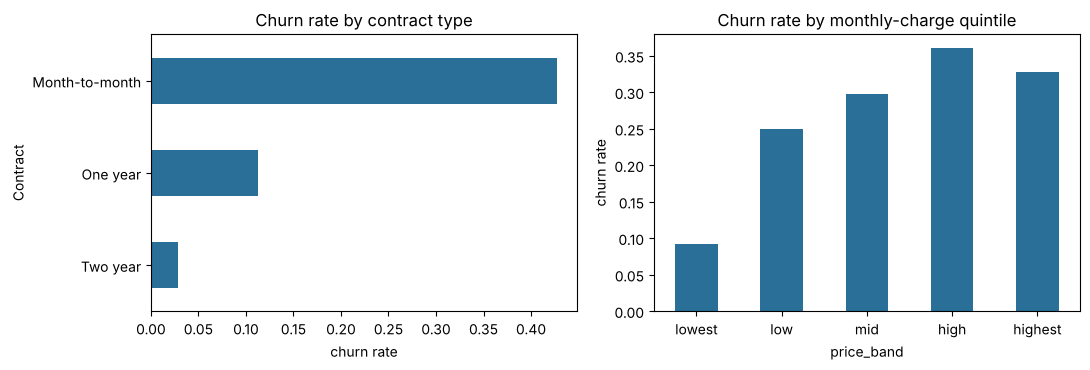

In [3]:
df["price_band"] = pd.qcut(df.MonthlyCharges, 5, labels=["lowest", "low", "mid", "high", "highest"])
band = df.groupby("price_band", observed=True).Churn.mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
df.groupby("Contract").Churn.mean().sort_values().plot.barh(ax=ax[0], color="#2a6f97")
ax[0].set_title("Churn rate by contract type"); ax[0].set_xlabel("churn rate")
band.plot.bar(ax=ax[1], color="#2a6f97", rot=0)
ax[1].set_title("Churn rate by monthly-charge quintile"); ax[1].set_ylabel("churn rate")
plt.tight_layout(); plt.savefig("../reports/figures/01_churn_concentration.png", dpi=140); plt.show()

## Takeaways to carry forward
- Contract type is the dominant signal: month-to-month customers churn far more than annual contracts.
- Churn rises with monthly charge, but price is confounded with service type (e.g. fibre costs more), so notebook 04 estimates the price effect with those controls and reports uncertainty.
- **Leakage warning:** `tenure` and `TotalCharges` are only known after the customer has stayed. For churners, `tenure` *is* how long they lasted. Notebook 02 therefore predicts from signup-time features only; notebook 03 uses tenure properly as time-to-event.